In [95]:
import math
from matplotlib import pyplot as plt
from dataclasses import dataclass
from IPython.display import Audio

## Модель аддитивного синтезатора звука в реализации на плавающей точке

1. 1 осциллятор синуса
2. 4 осциллятора, орган
3. Экспоненциальное затухание
4. Мелодия
5. Решение проблемы щелчков

Вспомогательные функции

In [96]:
def save_audio(filename, samples):
    with open(filename, "wb") as f:
        f.write(Audio(samples, rate=SR).data)

def show(y, title="Осциллограмма"):
    plt.figure(figsize=(16, 9))
    plt.plot(range(len(y)), y)
    plt.xlabel("Номер сэмпла")
    plt.ylabel("Амплитуда")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

### 1 осциллятор синуса

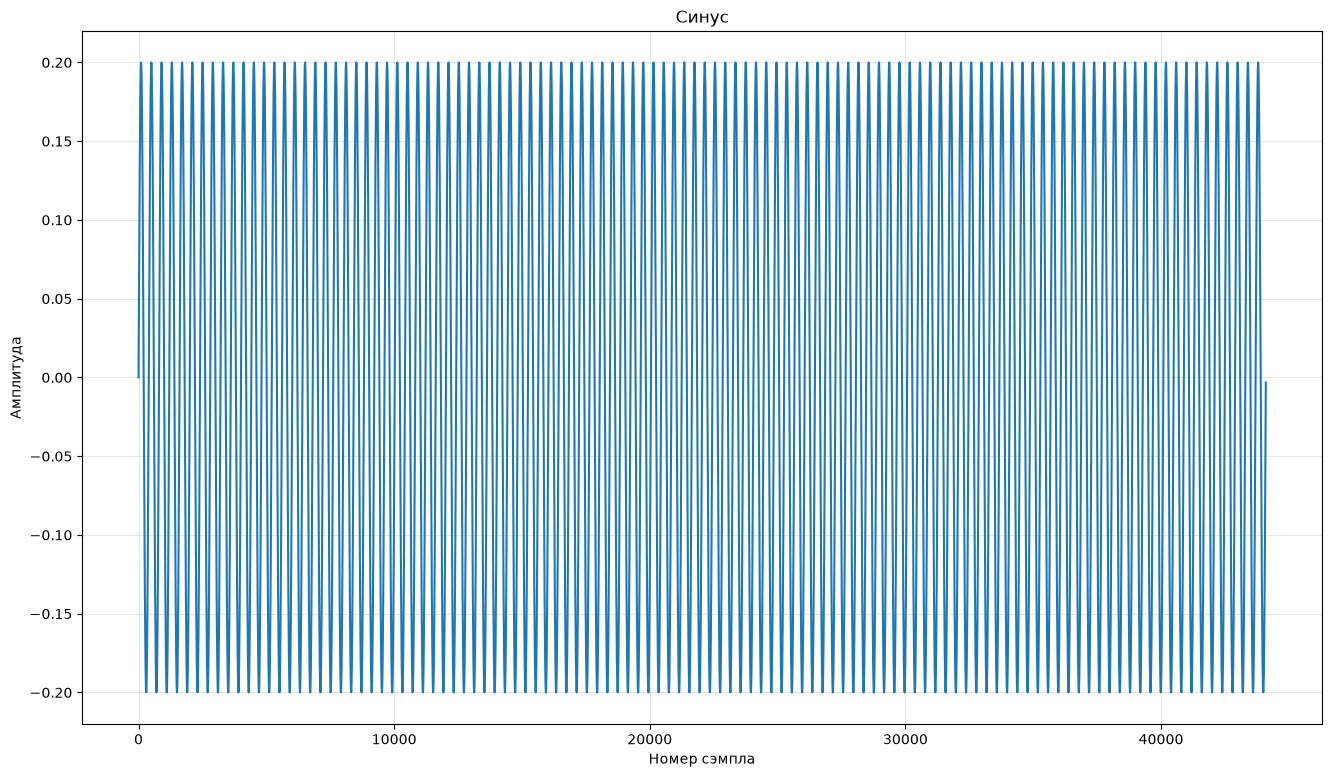

In [97]:
SR = 44100

def get_step(freq):
    return 2 * math.pi * freq / SR

# Объяляем класс осциллятора волны синуса
@dataclass
class OSC:
    amp: float       # Громкость
    step: float      # Шаг изменения фазы синуса
    phase: float = 0 # Фаза синуса

# Нота A2 (110 Гц)
osc = OSC(amp=0.2, step=get_step(110))

# Функция для генерации сэмпла на основе текущего состояния синтезатора
def get_sample(osc):
    sample = osc.amp * math.sin(osc.phase)
    osc.phase += osc.step
    return sample

samples = [get_sample(osc) for _ in range(SR)]

show(samples, title="Синус")
Audio(samples, rate=SR, normalize=False)

### 4 осциллятора синуса, орган

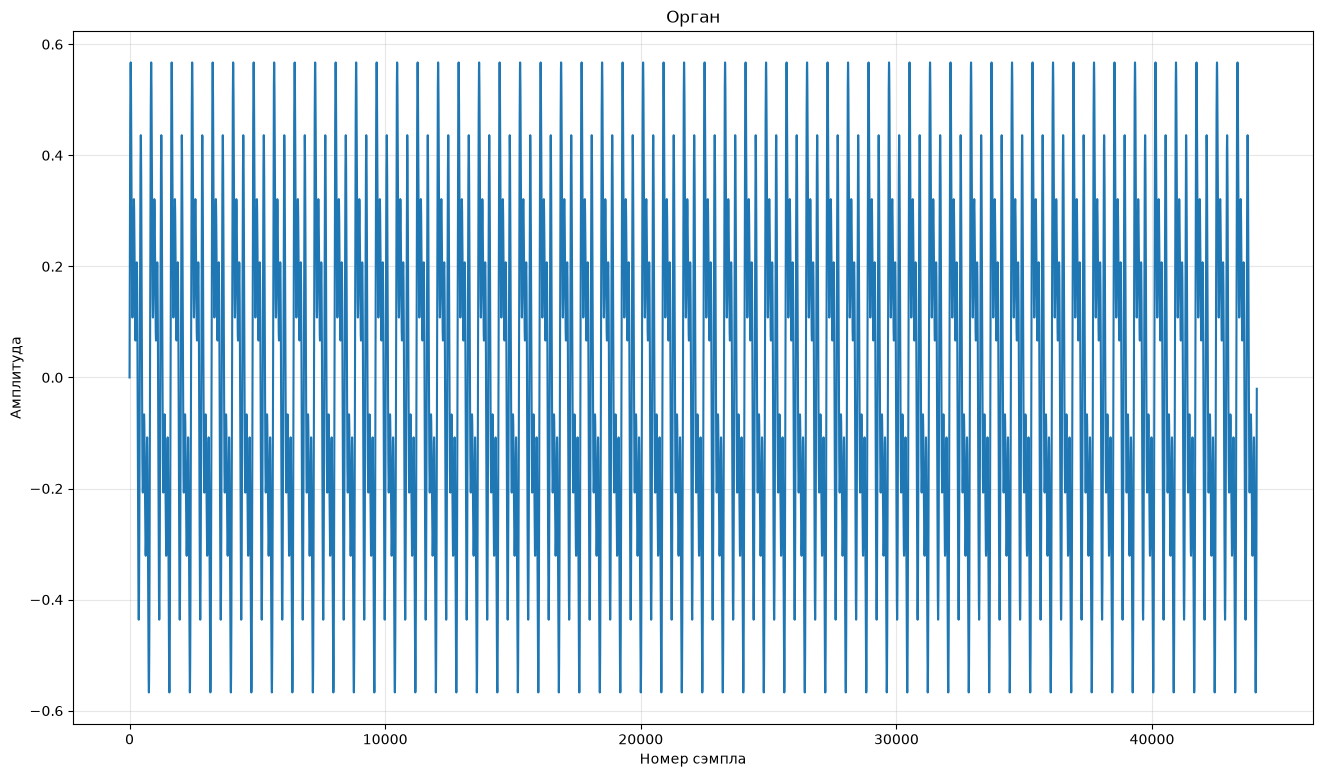

In [98]:
# Теперь осцилляторов несколько.
voices = [ 
    OSC(amp=0.2, step=get_step(110)),
    OSC(amp=0.2, step=get_step(110 * 0.5)),
    OSC(amp=0.2, step=get_step(110 * 2)),
    OSC(amp=0.2, step=get_step(110 * 3)),
]

def get_sample(voices):
    acc = 0
    for osc in voices:
        acc += osc.amp * math.sin(osc.phase)
        osc.phase += osc.step
    return acc

samples = [get_sample(voices) for _ in range(SR)]

show(samples, title="Орган")
Audio(samples, rate=SR, normalize=False)

### Экспоненциальное затухание

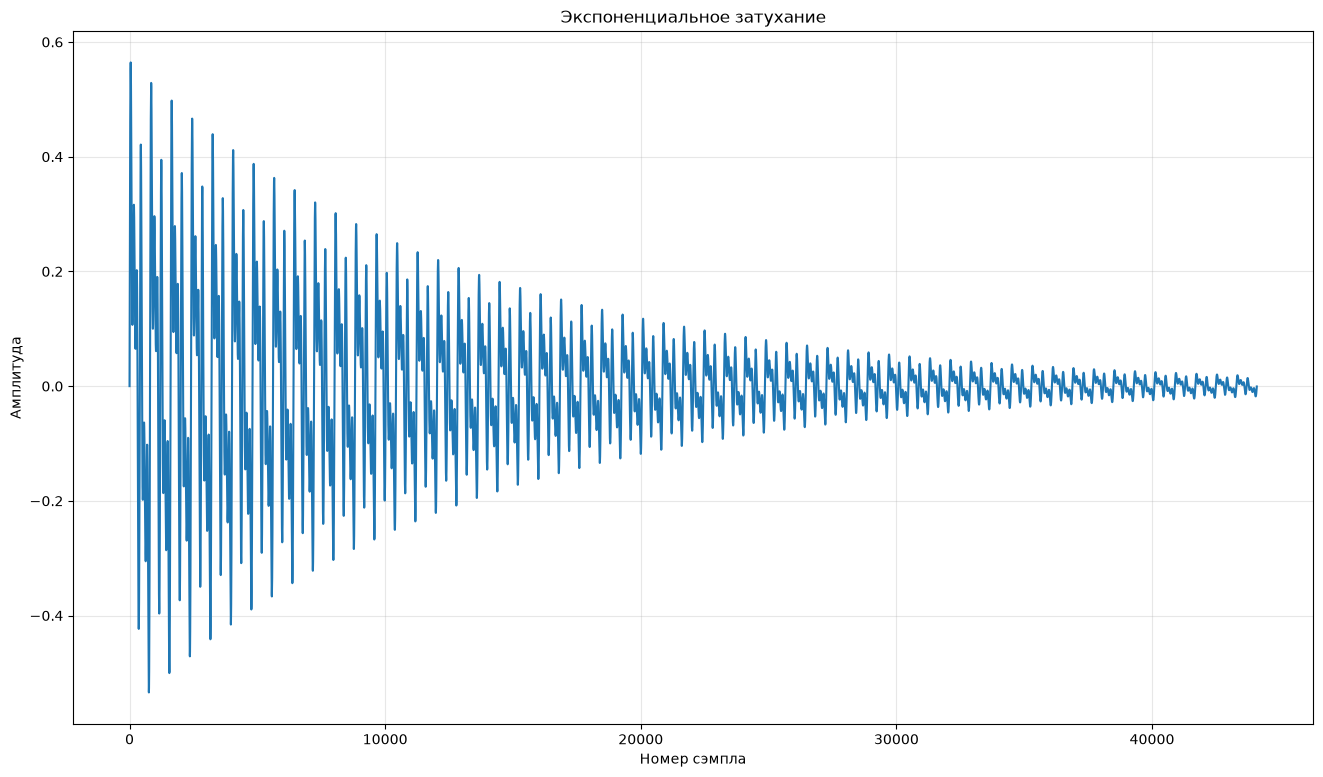

In [99]:
@dataclass
class OSC:
    amp: float
    step: float
    decay: float     # Коэффициент затухания
    phase: float = 0

voices = [
    OSC(amp=0.2, step=get_step(110),       decay=0.995),
    OSC(amp=0.2, step=get_step(110 * 0.5), decay=0.995),
    OSC(amp=0.2, step=get_step(110 * 2),   decay=0.995),
    OSC(amp=0.2, step=get_step(110 * 3),   decay=0.995),
]

def get_sample(sample_num, voices):
    acc = 0
    for osc in voices:
        acc += osc.amp * math.sin(osc.phase)
        osc.phase += osc.step
        if sample_num % 64 == 0:
            osc.amp *= osc.decay
    return acc

samples = [get_sample(i, voices) for i in range(SR)]

show(samples, title="Экспоненциальное затухание")
Audio(samples, rate=SR, normalize=False)

### Мелодия

In [100]:
SONG = "E-4 E-4 F-4 G-4 G-4 F-4 E-4 D-4 C-4 C-4 D-4 E-4 E-4 D-4 D-4"

Вспомогательные функции для преобразования мелодии из нот в частоту синуса

In [103]:
NOTES_IN_OCTAVE = dict(zip("c- c# d- d# e- f- f# g- g# a- a# b-".split(),
                   range(12)))

BPM = 120
NOTE_DURATION = 60 / BPM

def midi2freq(m):
    return 440 * 2 ** ((m - 69) / 12)

def note2freq(note):
    note_in_octave, octave_number = note[:2].lower(), int(note[2])
    return midi2freq(NOTES_IN_OCTAVE[note_in_octave] + 12 * (octave_number + 1))

freqs = [note2freq(x) for x in SONG.split()]

Появление параметра abs и необходимость во внутренних параметрах синтезатора

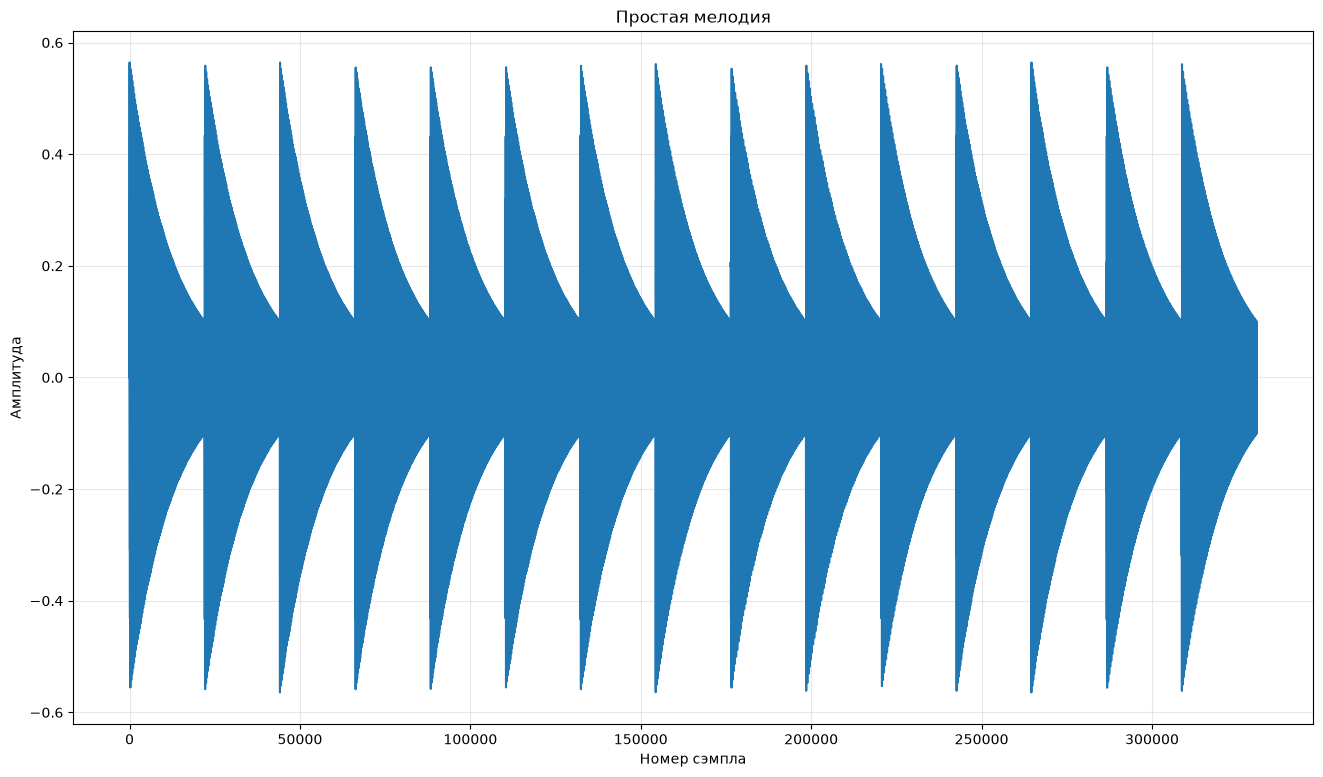

In [106]:
@dataclass
class OSC:
    # Параметры осциллятора
    abs: bool       # Абсолютные/относительные параметры
    osc_amp: float  # Абсолютная/относительная громкость
    osc_step: float # Абсолютный/относительный шаг
    decay: float    # Коэффициент затухания
    # Внутренние абсолютные параметры синтезатора (получаются в update_voices)
    amp: float = 0        # Текущая громкость
    phase: float = 0      # Фаза
    step: float = 0       # Шаг


DECAY = 0.995
# У slave-осцилляторов amp и step задаются относительно master-осциллятора
voices = [
    OSC(abs=True,  osc_amp=0.2, decay=DECAY, osc_step=get_step(110)), # master
    OSC(abs=False, osc_amp=1,   decay=DECAY, osc_step=0.5),           # slave
    OSC(abs=False, osc_amp=1,   decay=DECAY, osc_step=2),             # slave
    OSC(abs=False, osc_amp=1,   decay=DECAY, osc_step=3),             # slave
]

def update_voices(voices, freq):
    abs = None
    for osc in voices:
        if osc.abs:
            abs = osc
            osc.step = get_step(freq)
            osc.amp = osc.osc_amp
        else:
            osc.step = abs.step * osc.osc_step
            osc.amp = abs.amp * osc.osc_amp

samples = []

for freq in freqs:
    update_voices(voices, freq)
    for i in range(int(NOTE_DURATION * SR)):
        samples.append(get_sample(i, voices))

show(samples, title="Простая мелодия")
Audio(samples, rate=SR, normalize=False)

### Решение проблемы щелчков

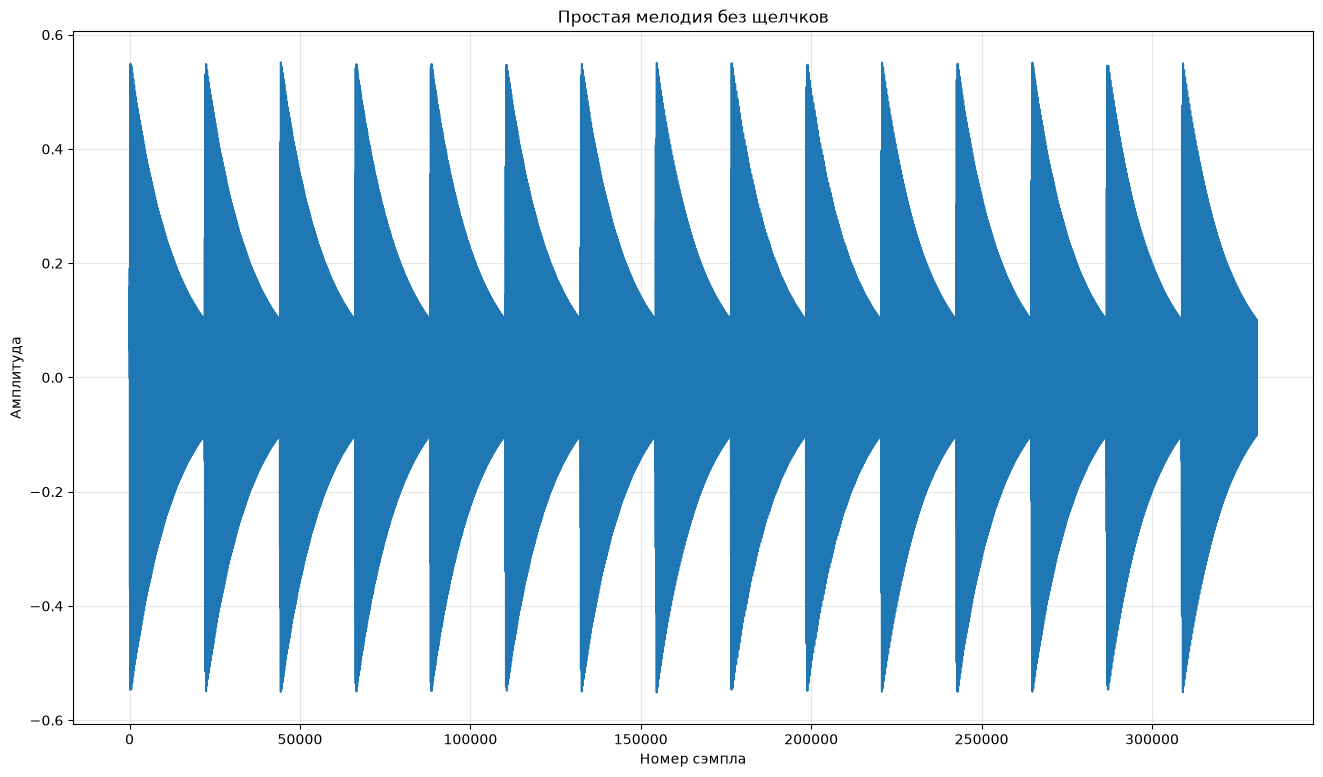

In [107]:
@dataclass
class OSC:
    abs: bool
    osc_amp: float
    osc_step: float
    decay: float

    target_amp: float = 0 # Целевая громкость
    amp: float = 0
    phase: float = 0
    step: float = 0


voices = [
    OSC(abs=True,  osc_amp=0.2, decay=DECAY, osc_step=get_step(110)), # master
    OSC(abs=False, osc_amp=1,   decay=DECAY, osc_step=0.5),           # slave
    OSC(abs=False, osc_amp=1,   decay=DECAY, osc_step=2),             # slave
    OSC(abs=False, osc_amp=1,   decay=DECAY, osc_step=3),             # slave
]

def update_voices(voices, freq):
    abs = None
    for osc in voices:
        if osc.abs:
            abs = osc
            osc.step = get_step(freq)
            osc.target_amp = osc.osc_amp                  # было osc.amp = ...
        else:
            osc.step = abs.step * osc.osc_step
            osc.target_amp = abs.target_amp * osc.osc_amp # было osc.amp = ...

def get_sample(sample_num, voices):
    acc = 0
    for osc in voices:
        osc.amp += (osc.target_amp - osc.amp) / 64 # защита от кликов
        acc += osc.amp * math.sin(osc.phase)
        osc.phase += osc.step
        if sample_num % 64 == 0:
            osc.target_amp *= osc.decay
    return acc

samples = []

for freq in freqs:
    update_voices(voices, freq)
    for i in range(int(NOTE_DURATION * SR)):
        samples.append(get_sample(i, voices))

show(samples, title="Простая мелодия без щелчков")
Audio(samples, rate=SR, normalize=False)

In [93]:
MELODY  = "E-5 E-5 F-5 G-5 G-5 F-5 E-5 D-5 C-5 C-5 D-5 E-5 E-5 D-5 D-5"
BASS    = "C-3 C-3 C-3 C-3 C-3 C-3 G-2 G-2 A-2 A-2 A-2 A-2 G-2 G-2 C-3"
HARMONY = "G-3 G-3 A-3 B-3 B-3 A-3 G-3 F-3 E-3 E-3 F-3 G-3 G-3 F-3 F-3"

violin_freqs = [note2freq(x) for x in MELODY.split()]
cello_freqs = [note2freq(x) for x in BASS.split()]
horn_freqs = [note2freq(x) for x in HARMONY.split()]

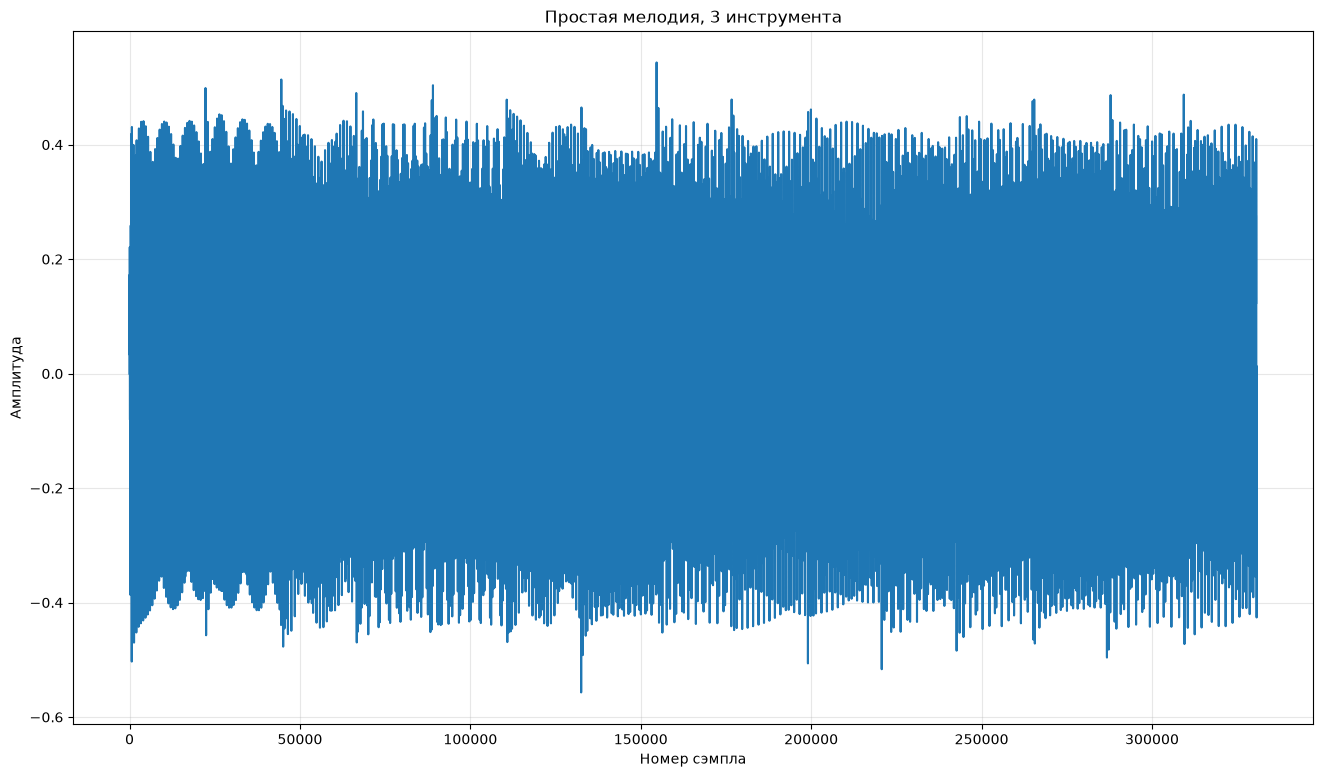

In [108]:
DECAY_MELODY = 0.99995
DECAY_BASS = 0.99998
DECAY_HARMONY = 0.9999

voices = [
    OSC(abs=True,  osc_amp=0.150, decay=DECAY_MELODY,         osc_step=0),
    OSC(abs=False, osc_amp=0.252, decay=DECAY_MELODY * 0.985, osc_step=2),
    OSC(abs=False, osc_amp=0.150, decay=DECAY_MELODY * 0.970, osc_step=3),
    OSC(abs=False, osc_amp=0.157, decay=DECAY_MELODY * 0.955, osc_step=4),
    OSC(abs=False, osc_amp=0.047, decay=DECAY_MELODY * 0.940, osc_step=5),
    OSC(abs=False, osc_amp=0.029, decay=DECAY_MELODY * 0.925, osc_step=6),

    OSC(abs=True,  osc_amp=0.150, decay=DECAY_BASS,         osc_step=0), 
    OSC(abs=False, osc_amp=0.252, decay=DECAY_BASS * 0.985, osc_step=2), 
    OSC(abs=False, osc_amp=0.268, decay=DECAY_BASS * 0.970, osc_step=3), 
    OSC(abs=False, osc_amp=0.347, decay=DECAY_BASS * 0.955, osc_step=4), 
    OSC(abs=False, osc_amp=0.157, decay=DECAY_BASS * 0.940, osc_step=5), 

    OSC(abs=True,  osc_amp=0.150, decay=DECAY_HARMONY,           osc_step=0),
    OSC(abs=False, osc_amp=0.651, decay=DECAY_HARMONY * 0.985,   osc_step=2),
    OSC(abs=False, osc_amp=0.276, decay=DECAY_HARMONY * 0.970,   osc_step=3),
    OSC(abs=False, osc_amp=0.177, decay=DECAY_HARMONY * 0.955,   osc_step=4),
    OSC(abs=False, osc_amp=0.129, decay=DECAY_HARMONY * 0.940,   osc_step=5),
]

samples = []

for freq_violin, freq_cello, freq_horn in zip(violin_freqs, cello_freqs, horn_freqs):
    update_voices(voices[:6], freq_violin)
    update_voices(voices[6:11], freq_cello)
    update_voices(voices[11:], freq_horn)
    for i in range(int(NOTE_DURATION * SR)):
        samples.append(get_sample(i, voices))

show(samples, title="Простая мелодия, 3 инструмента")
Audio(samples, rate=SR, normalize=False)